## Import

In [1]:
import kagglehub
from pathlib import Path

data_dir = Path("./Data")
data_dir.mkdir(parents=True, exist_ok=True)

if not any(data_dir.iterdir()):
    path = kagglehub.dataset_download(
        "kmader/finding-lungs-in-ct-data",
        output_dir=str(data_dir)
    )
    print("Dataset downloaded to:", path)
else:
    path = data_dir
    print("Dataset already exists at:", path.resolve())

Dataset already exists at: /nfs/s-l028/scratch/Users/jkitzmann/SlicerLab/Data


In [2]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.nn.functional as F
import copy
import random
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

device = 'cuda'

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132


## Helpful functions

In [3]:
def show_slice(image, segmentation=None, title=None, slice_num = None):

    # Handle PyTorch tensors
    if isinstance(image, torch.Tensor):
        im = image.squeeze().detach().cpu().numpy()
        seg = segmentation.squeeze().detach().cpu().numpy() if segmentation is not None else None

    # Handle SimpleITK images
    else:
        im = sitk.GetArrayFromImage(image)
        seg = sitk.GetArrayFromImage(segmentation) if segmentation is not None else None

    plt.figure(figsize=(7, 7))

    if slice_num == None:
        plt.imshow(im, cmap="gray")
    else:
        plt.imshow(im[slice_num], cmap='gray')
        
    plt.colorbar()
    if title != None:
        plt.title(title)


    if seg is not None:
        if slice_num == None:
            plt.imshow(
                np.ma.masked_where(seg == 0, seg),
                cmap="autumn",
                alpha=0.5
            )
        else:
            plt.imshow(
                np.ma.masked_where(seg[slice_num] == 0, seg[slice_num]),
                cmap="autumn",
                alpha=0.5
            )

    plt.axis("off")
    plt.show()


In [4]:
# stupid kaggle people screwed up the stupid image metadata AGH
def fix_orientation(image):
    a = sitk.GetArrayFromImage(image)
    b = a.transpose(2, 1, 0)[:, :, ::-1]
    sx, sy, sz = image.GetSpacing()

    fixed = sitk.GetImageFromArray(np.ascontiguousarray(b))
    fixed.SetSpacing((sz, sy, sx))
    fixed.SetOrigin((0.0, 0.0, 0.0))
    fixed.SetDirection((1, 0, 0, 0, 1, 0, 0, 0, 1))
    return fixed


# Orientation the model is trained in: LPS, i.e. array [z, y, x] =
# [inferior->superior, anterior->posterior, right->left], axial slices along
# axis 0. This is the layout of Slicer's sample CTs (e.g. CTChest), and the
# Slicer module reorients every input to it before segmenting.
CANONICAL_ORIENTATION = "LPS"


def load_kaggle_volume(path):
    """Read a Kaggle volume, fix its metadata, and put it in the canonical orientation."""
    return sitk.DICOMOrient(fix_orientation(sitk.ReadImage(str(path))), CANONICAL_ORIENTATION)


def normalize_slices(x, eps=1e-8):
    """Z-score each 2D slice independently (last two axes).

    The Slicer module uses this exact normalization at inference, so training
    must match it.
    """
    mean = x.mean(axis=(-2, -1), keepdims=True)
    std = x.std(axis=(-2, -1), keepdims=True)
    return (x - mean) / (std + eps)


def augment_slice(image, mask):
    """Random spatial + intensity augmentation for one slice.

    image: (1, H, W) float tensor of raw intensities, mask: (H, W) long tensor.
    Spatial transforms are applied identically to image and mask.
    """
    if random.random() < 0.5:
        image, mask = image.flip(-1), mask.flip(-1)

    h, w = image.shape[-2:]
    angle = random.uniform(-15, 15)
    translate = [int(random.uniform(-0.05, 0.05) * w), int(random.uniform(-0.05, 0.05) * h)]
    scale = random.uniform(0.85, 1.15)

    image = TF.affine(image, angle=angle, translate=translate, scale=scale, shear=[0.0],
                      interpolation=InterpolationMode.BILINEAR, fill=[float(image.min())])
    mask = TF.affine(mask[None].float(), angle=angle, translate=translate, scale=scale, shear=[0.0],
                     interpolation=InterpolationMode.NEAREST, fill=[0.0])[0].round().long()

    # intensity: contrast, brightness, noise (relative to slice spread)
    std = image.std()
    image = image * random.uniform(0.9, 1.1) + random.uniform(-0.1, 0.1) * std
    image = image + torch.randn_like(image) * random.uniform(0, 0.03) * std

    return image, mask

## Dataset

In [5]:
image_dir = Path(path) / "3d_images"

image_files = sorted(image_dir.glob("IMG_*.nii.gz"))
mask_files = sorted(image_dir.glob("MASK_*.nii.gz"))

In [6]:
images = {
    f.name.replace("IMG_", "").replace(".nii.gz", ""): f
    for f in image_files
}

masks = {
    f.name.replace("MASK_", "").replace(".nii.gz", ""): f
    for f in mask_files
}

assert images.keys() == masks.keys(), "ids don't match"

volume_pairs = [
    (images[volume_id], masks[volume_id])
    for volume_id in sorted(images)
]

print(f"Successfully paired {len(volume_pairs)} volumes.")

Successfully paired 4 volumes.


In [7]:
class LungDataset(Dataset):

    def __init__(self, volume_pairs, augment=False):
        self.augment = augment
        self.images = []
        self.masks = []
        self.slice_indices = []

        for image_file, mask_file in volume_pairs:

            image = load_kaggle_volume(image_file)
            mask = load_kaggle_volume(mask_file)

            # arrays are [z, y, x]; axial slices along axis 0
            image = sitk.GetArrayFromImage(image).astype(np.float32)
            mask = sitk.GetArrayFromImage(mask).astype(np.int32)
            mask = (mask > 0).astype(np.uint8)

            self.images.append(image)
            self.masks.append(mask)

            volume_idx = len(self.images) - 1

            for z in range(image.shape[0]):
                self.slice_indices.append((volume_idx, z))

    def __len__(self):
        return len(self.slice_indices)

    def __getitem__(self, idx):

        volume_idx, slice_idx = self.slice_indices[idx]

        image = torch.from_numpy(self.images[volume_idx][slice_idx].copy()).float().unsqueeze(0)
        mask = torch.from_numpy(self.masks[volume_idx][slice_idx].copy()).long()

        if self.augment:
            image, mask = augment_slice(image, mask)

        image = normalize_slices(image)

        return image, mask

Total slices: 1208
Image shape: torch.Size([1, 512, 512])
Mask shape: torch.Size([512, 512])


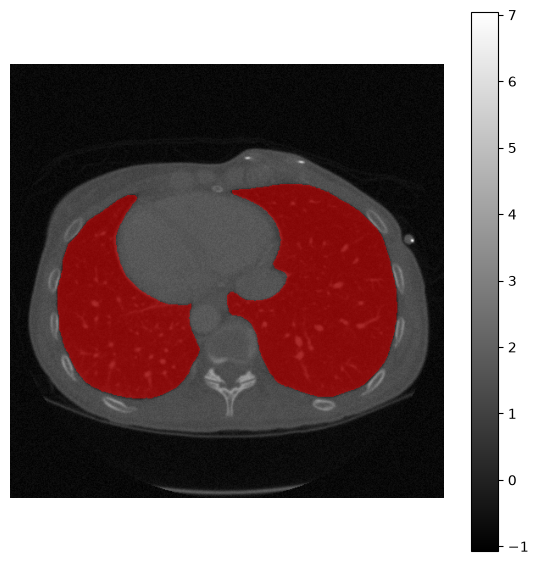

In [8]:
dataset = LungDataset(volume_pairs)

print("Total slices:", len(dataset))

image, mask = dataset[80]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

show_slice(image, mask)

## Split

In [9]:
train_pairs, val_pairs = train_test_split(
    volume_pairs,
    test_size=0.25,
    random_state=42
)

train_dataset = LungDataset(train_pairs, augment=True)
val_dataset = LungDataset(val_pairs)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training volumes:", len(train_pairs))
print("Validation volumes:", len(val_pairs))
print("Training slices:", len(train_dataset))
print("Validation slices:", len(val_dataset))

Training volumes: 3
Validation volumes: 1
Training slices: 743
Validation slices: 465


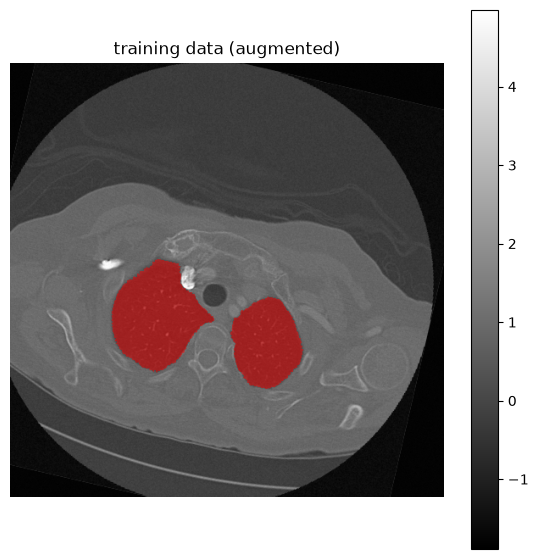

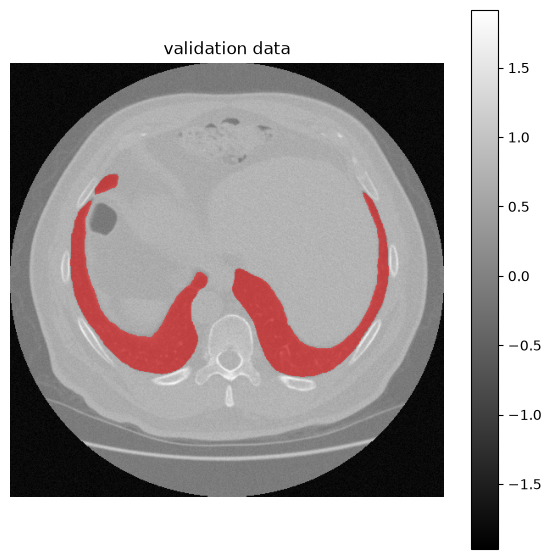

In [10]:
# Index each dataset once: every train_dataset[i] call draws a new random
# augmentation, so [i][0] and [i][1] from separate calls would not match.
image, mask = train_dataset[100]
show_slice(image, mask, title='training data (augmented)')

image, mask = val_dataset[100]
show_slice(image, mask, title='validation data')

## U-Net

In [11]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


In [12]:

class UNet2D(nn.Module):
    def __init__(self, in_channels=1, num_classes=2, features=32):
        super().__init__()

        # encoder
        self.enc1 = DoubleConv(in_channels, features)
        self.enc2 = DoubleConv(features, features * 2)
        self.enc3 = DoubleConv(features * 2, features * 4)
        self.enc4 = DoubleConv(features * 4, features * 8)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # bottleneck
        self.bottleneck = DoubleConv(features * 8, features * 16)

        # decoder
        self.up4 = nn.ConvTranspose2d(features * 16, features * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(features * 16, features * 8)

        self.up3 = nn.ConvTranspose2d(features * 8, features * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(features * 8, features * 4)

        self.up2 = nn.ConvTranspose2d(features * 4, features * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(features * 4, features * 2)

        self.up1 = nn.ConvTranspose2d(features * 2, features, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(features * 2, features)

        # classification
        self.out = nn.Conv2d(features, num_classes, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = F.interpolate(d4, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = F.interpolate(d3, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = F.interpolate(d2, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = F.interpolate(d1, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


## Train

In [13]:
def run_epoch(model, loader, criterion, device, optimizer=None):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_samples = 0

    # Accumulate foreground Dice statistics
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        if training:
            optimizer.zero_grad()

        # Forward pass
        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, masks)

            if training:
                loss.backward()
                optimizer.step()

        # Accumulate loss
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        # Convert logits into predicted class labels
        predictions = outputs.argmax(dim=1)

        # Calculate foreground statistics
        total_tp += ((predictions == 1) & (masks == 1)).sum().item()
        total_fp += ((predictions == 1) & (masks == 0)).sum().item()
        total_fn += ((predictions == 0) & (masks == 1)).sum().item()

    # Epoch-level metrics
    epoch_loss = total_loss / total_samples

    dice = (2 * total_tp + 1e-8) / (
        2 * total_tp + total_fp + total_fn + 1e-8
    )

    return epoch_loss, dice


In [14]:
model = UNet2D(
    in_channels=1,
    num_classes=2,
    features=32
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

num_epochs = 25
best_val_dice = -1.0

history = {
    'train_loss': [],
    'val_loss': [],
    'train_dice': [],
    'val_dice': []
}

for epoch in range(num_epochs):

    train_loss, train_dice = run_epoch(
        model, train_loader, criterion, device, optimizer
    )

    val_loss, val_dice = run_epoch(
        model, val_loader, criterion, device
    )

    # Store metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    # Save best model
    if val_dice > best_val_dice:
        best_val_dice = val_dice

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": val_dice
        }, "best_unet2d.pth")

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

print(f"\nBest validation Dice: {best_val_dice:.4f}")


Epoch [01/25] Train Loss: 0.3743 | Val Loss: 0.3482 | Train Dice: 0.7628 | Val Dice: 0.2643
Epoch [02/25] Train Loss: 0.2351 | Val Loss: 0.3360 | Train Dice: 0.9648 | Val Dice: 0.3277
Epoch [03/25] Train Loss: 0.1960 | Val Loss: 0.3145 | Train Dice: 0.9777 | Val Dice: 0.3437
Epoch [04/25] Train Loss: 0.1713 | Val Loss: 0.3122 | Train Dice: 0.9741 | Val Dice: 0.2592
Epoch [05/25] Train Loss: 0.1445 | Val Loss: 0.3500 | Train Dice: 0.9828 | Val Dice: 0.1210
Epoch [06/25] Train Loss: 0.1267 | Val Loss: 0.2415 | Train Dice: 0.9822 | Val Dice: 0.6048
Epoch [07/25] Train Loss: 0.1080 | Val Loss: 0.1048 | Train Dice: 0.9858 | Val Dice: 0.9616
Epoch [08/25] Train Loss: 0.0926 | Val Loss: 0.2447 | Train Dice: 0.9887 | Val Dice: 0.5591
Epoch [09/25] Train Loss: 0.0822 | Val Loss: 0.2010 | Train Dice: 0.9886 | Val Dice: 0.6816
Epoch [10/25] Train Loss: 0.0714 | Val Loss: 0.2271 | Train Dice: 0.9900 | Val Dice: 0.5878
Epoch [11/25] Train Loss: 0.0650 | Val Loss: 0.1415 | Train Dice: 0.9882 | Val D

KeyboardInterrupt: 

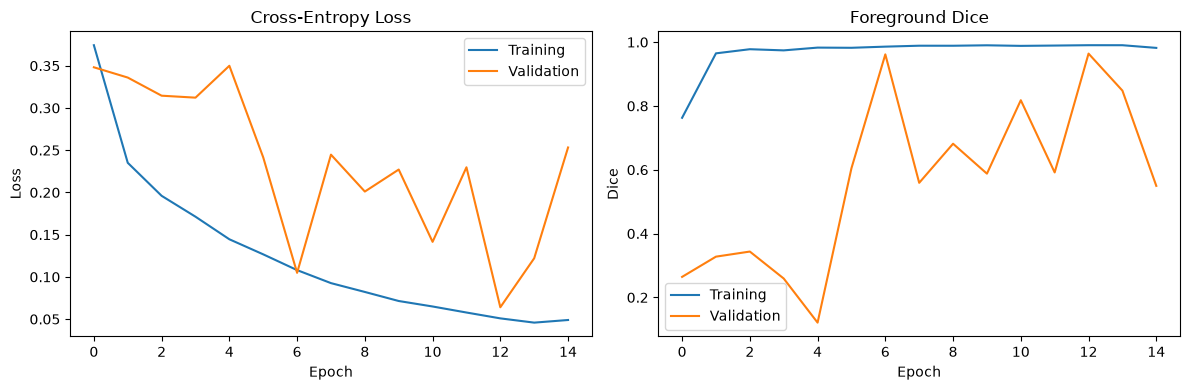

In [15]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history["train_loss"], label="Training")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Dice
axes[1].plot(history["train_dice"], label="Training")
axes[1].plot(history["val_dice"], label="Validation")
axes[1].set_title("Foreground Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()

plt.tight_layout()
plt.show()


# Apply to validation image

In [16]:
checkpoint = torch.load(
    'best_unet2d.pth',
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

UNet2D(
  (enc1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
 

In [17]:
def predict_volume(model, image, device, batch_size=8):
    """Segment a SimpleITK image of any orientation.

    The image is reoriented to CANONICAL_ORIENTATION, segmented slice by slice,
    and the prediction is reoriented back. The returned array has the same
    [k, j, i] layout as sitk.GetArrayFromImage(image). Same as SlicerLab.py.
    """
    original_orientation = (
        sitk.DICOMOrientImageFilter_GetOrientationFromDirectionCosines(
            image.GetDirection()
        )
    )
    canonical = sitk.DICOMOrient(image, CANONICAL_ORIENTATION)

    volume = sitk.GetArrayFromImage(canonical).astype(np.float32)
    prediction = np.zeros(volume.shape, dtype=np.uint8)

    model.eval()

    with torch.no_grad():
        for start in range(0, volume.shape[0], batch_size):
            end = min(start + batch_size, volume.shape[0])

            # Axial slices (array is [z, y, x])
            slices = normalize_slices(volume[start:end])

            inputs = torch.from_numpy(slices.copy()).float().unsqueeze(1).to(device)

            outputs = model(inputs)
            prediction[start:end] = outputs.argmax(dim=1).cpu().numpy()

    prediction_image = sitk.GetImageFromArray(prediction)
    prediction_image.CopyInformation(canonical)
    prediction_image = sitk.DICOMOrient(prediction_image, original_orientation)

    return sitk.GetArrayFromImage(prediction_image)

## Try on full 3D volume

In [18]:
test_im = load_kaggle_volume(image_files[3])

prediction = predict_volume(
    model,
    test_im,
    device,
    batch_size=8
)

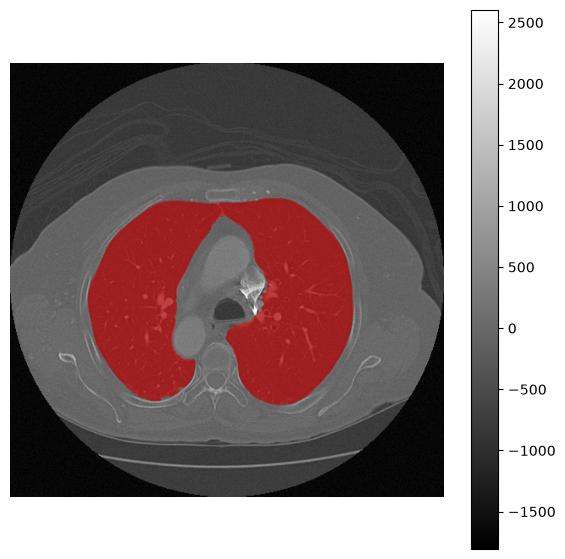

In [19]:
show_slice(test_im, sitk.GetImageFromArray(prediction), slice_num=80)